# Compute Distances to Resected area

## Imports

In [3]:
import mindmap as mm 
import mne
from pathlib import Path
import pandas as pd
import numpy as np
import pyvista as pv
import seaborn as sns
import matplotlib.pyplot as plt

## Data

In [4]:
# configuration
config = mm.io.read_config("../../configurations/spike.yml")
sub = config["SUBS"][3]

# data
data = mm.io.read_dataset(sub, "src", "sloreta", "cset", "cset_error2", "cset_error1", "resec", "eeg_inv")

sfreq = data["eeg_inv"].info["sfreq"]

_, ht = mm.utils.eeg_rising_phase(data["eeg_inv"], ratio=0.5)
_, pt = mm.utils.eeg_rising_phase(data["eeg_inv"], ratio=1)

t_half = ht/sfreq 
t_peak = pt/sfreq

print(f"50% rising phase time: {t_half:03}")
print(f"Peak time: {t_peak:03}")

No resection found for subject sub-pat04'
Some arguments did not correpond to the list of available objects to load. Check the list of arguments again.
50% rising phase time: 0.484
Peak time: 0.5


## Visualize Reconstruction

In [45]:
recon = data["cset"]

mm.viz.plot_brain_time_series(data["src"], np.abs(recon.data), cmap="Reds", sfreq=sfreq, t_start=t_peak-0.05)

Widget(value='<iframe src="http://localhost:38847/index.html?ui=P_0x7ed6ea3d3560_28&reconnect=auto" class="pyv…

## Utilities

In [2]:
def measure_distance(target_point, target_area, x=100):
    distances = target_area-target_point

    if x == "all":
        mean_distance = np.mean(distances, axis=0)
        norm          = np.linalg.norm(mean_distance)

    else:
        norms         = np.linalg.norm(distances, ord=2, axis=1)
        nearest       = distances[np.argsort(norms)[:x],:]
        mean_distance = np.mean(nearest, axis=0)
        norm          = np.linalg.norm(mean_distance)

    return norm

def select_source_estimate(stc, sources, tp):

    time_idx = np.argmin(np.abs(stc.times-tp))
    src_idx  = np.argmax(np.abs(stc.data[:,time_idx]))

    time_point      = stc.times[time_idx]
    brain_activity  = stc.data[:, time_idx]
    source_estimate = mm.utils.get_src_position(sources)[src_idx]

    return time_point, brain_activity, source_estimate


#def select_source_estimate2(stc, sources, tp, n=100):
#    time_idx = np.argmin(np.abs(stc.times-tp))
#    
#    time_point     = stc.times[time_idx]
#    brain_activity = stc.data[:,time_idx]
#
#    # closest dipoles in left hemisphere
#    lh_dist  = sources[0]["dist"][sources[0]["vertno"]][:,sources[0]["vertno"]].todense()
#    lh_neigh = np.argsort(lh_dist)[:,:n+1]
#
#    # closest dipoles in right hemisphere
#    rh_dist  = sources[1]["dist"][sources[1]["vertno"]][:,sources[1]["vertno"]].todense()
#    rh_neigh = np.argsort(rh_dist)[:,:n+1]
#    rh_neigh = rh_neigh + len(sources[0]["vertno"])
#
#    neigh = np.vstack([lh_neigh, rh_neigh])
#
#    score   = np.average(brain_activity[neigh], axis=1)
#    src_idx = np.argmax(score)
#
#    source_estimate = mm.utils.get_src_position(sources)[src_idx]
#
#    return time_point, brain_activity, source_estimate

## Compute distance

In [40]:
# select source reconstruction
recon = data["cset"]

In [51]:
# source estimate
tp, ba, se = select_source_estimate(recon, data["src"], tp=t_half)

# cloud point of resected area
hole = np.argwhere(data["resec"].get_fdata()>0)
hole = mne.transforms.apply_trans(data["resec"].affine, hole)/1000      # cras?

# distance
dist = measure_distance(se, hole, x=1)
print(f"Distance Error: {dist*1000:.1f} mm, or {dist:.4f} m")
print(f"Selected time point: {tp:.3f} s")

# plot
plotter = mm.viz.plot_brain_signal(data["src"], np.abs(ba), cmap="Reds")
#plotter.add_mesh(pv.PolyData(hole), style="points_gaussian", point_size=5,  emissive=True, color="purple", label="Resected Area")
plotter.add_mesh(pv.PolyData(se), render_points_as_spheres=True, point_size=20, color="green", label="Source Estimation")
plotter.add_legend(face="circle")
plotter.show()

Distance Error: 2.0 mm, or 0.0020 m
Selected time point: 0.474 s


Widget(value='<iframe src="http://localhost:45207/index.html?ui=P_0x725a6c98d8e0_18&reconnect=auto" class="pyv…

## Create Distance Plot

In [18]:
subjects = [f"sub-pat{i+1:02d}" for i in range(28)]


distances = np.inf*np.ones((len(subjects),4))
for i,sub in enumerate(subjects):
    try:
        data = mm.io.read_dataset(sub, "src", "sloreta", "cset", "cset_error2", "cset_error1", "eeg_inv", "resec")

        sfreq  = data["eeg_inv"].info["sfreq"]
        _, ht  = mm.utils.eeg_rising_phase(data["eeg_inv"], ratio=0.5)
        t_half = ht/sfreq 

        _, _, sloreta = select_source_estimate(data["sloreta"], data["src"], tp=t_half)
        _, _, cset    = select_source_estimate(data["cset"], data["src"], tp=t_half)
        _, _, cset2   = select_source_estimate(data["cset_error2"], data["src"], tp=t_half)
        _, _, cset3   = select_source_estimate(data["cset_error1"], data["src"], tp=t_half)

        resec = np.argwhere(data["resec"].get_fdata()>0)
        resec = mne.transforms.apply_trans(data["resec"].affine, resec)/1000

        distances[i,0] = measure_distance(sloreta, resec, x=1)*100
        distances[i,1] = measure_distance(cset, resec, x=1)*100
        distances[i,2] = measure_distance(cset2, resec, x=1)*100
        distances[i,3] = measure_distance(cset3, resec, x=1)*100
        
    except Exception as e:
        print(f"Subject {sub} failed because {e}")
        distances[i] = None

distances = pd.DataFrame(distances, columns=["sLORETA", "CSET", "CSET*", "CSET**"])

# OHBM subjects:
id = [7, 8, 9, 13, 16, 25, 10, 19]
distances["CSET***"] = None
distances["CSET***"][id] = distances["CSET**"][id]

Subject sub-pat01 failed because File does not exist: "/media/nino/DATA/SPIKE/derivatives/mindmap/sub-pat01/fwd/sub-pat01_bem-sim-fwd.fif"
No resection found for subject sub-pat02'
Some arguments did not correpond to the list of available objects to load. Check the list of arguments again.
Subject sub-pat02 failed because 'resec'
No resection found for subject sub-pat04'
Some arguments did not correpond to the list of available objects to load. Check the list of arguments again.
Subject sub-pat04 failed because 'resec'
No resection found for subject sub-pat07'
Some arguments did not correpond to the list of available objects to load. Check the list of arguments again.
Subject sub-pat07 failed because 'resec'
No resection found for subject sub-pat18'
Some arguments did not correpond to the list of available objects to load. Check the list of arguments again.
Subject sub-pat18 failed because 'resec'
No resection found for subject sub-pat19'
Some arguments did not correpond to the list of

/tmp/ipykernel_7924/1703942261.py:35: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  distances["CSET***"][id] = distances["CSET**"][id]


[Text(0, 0.5, 'Localisation error [cm]')]

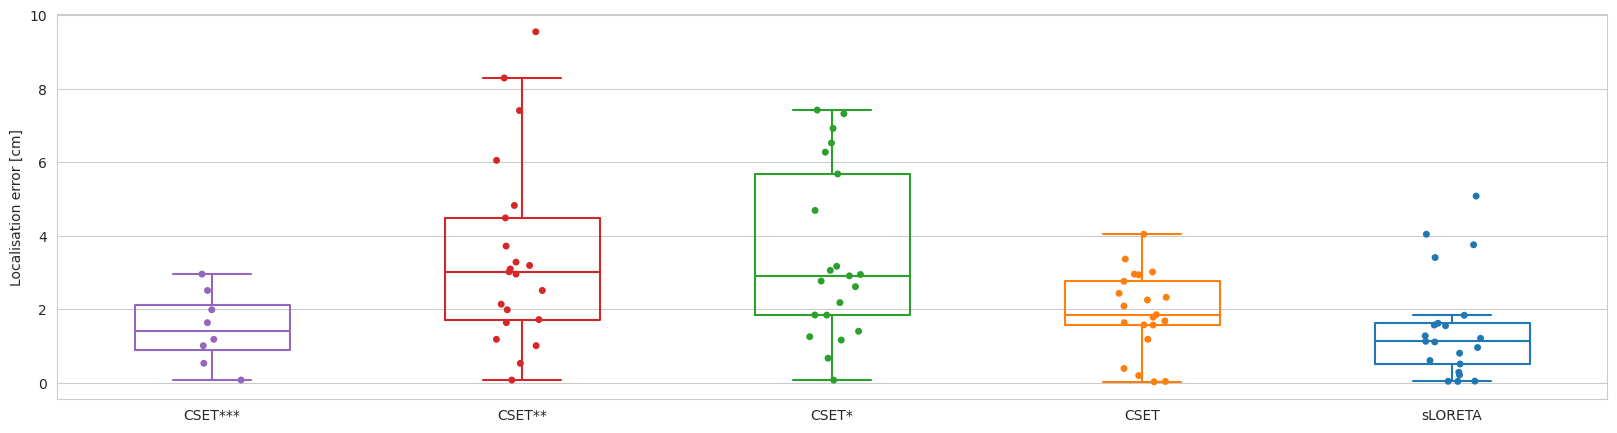

In [33]:
plt.figure(figsize=(20, 5))
sns.set_style("whitegrid")
ax  = sns.boxplot(data=distances, order=["CSET***", "CSET**", "CSET*",  "CSET", "sLORETA"], fill=False, showfliers=False, width=0.5)
ax2 = sns.stripplot(data=distances, order=["CSET***", "CSET**", "CSET*",  "CSET", "sLORETA"])

ax.set(ylabel="Localisation error [cm]")